# Single-slice tutorial: mouse liver MERFISH

This tutorial runs GASTON-VI on one slice of mouse liver MERFISH data (367,335 cells,
347 genes). In the liver, gene expression changes along the axis between the portal
vein and the central vein, so we expect the isodepth to recover this axis.

We will:

1. prepare the data
2. train the model
3. score the isodepth against known liver markers (AUPRC)
4. plot the isodepth
5. plot `f(d)` for example genes, with binned data and raw expression maps

## Data

Sign in with a Google account, then download `Liver1Slice1_cell_by_gene.csv` and
`Liver1Slice1_cell_metadata.csv` from
[Vizgen's liver showcase](https://console.cloud.google.com/storage/browser/vz-liver-showcase/Liver1Slice1)
into one folder.

Run this notebook from the `notebooks/` folder, and set the two paths below.

In [1]:
import glob
import sys

import matplotlib.pyplot as plt
import matplotlib.tri as mtri
import numpy as np
import pandas as pd
import torch
from scipy.special import logsumexp
from sklearn.metrics import average_precision_score

sys.path.insert(0, "..")
from gaston_vi.model.gaston_vi import GASTON_VI

plt.rcParams["figure.dpi"] = 150

DATA_DIR = "/path/to/mouse_liver_merfish"
RESULTS_DIR = "/path/to/results"

## 1. Prepare the data

GASTON-VI takes raw counts, so no normalization is needed. This cell turns the two
downloaded tables into the three arrays that `train.py` reads:

1. Read both tables and put the cells in the same order, because the two files list them
   differently.
2. Keep cells with at least 50 barcodes in total, counting the `Blank-*` control barcodes.
   This keeps 367,335 of 395,215 cells.
3. Drop the 38 `Blank-*` control barcodes, which leaves 347 genes.
4. Use `center_x` and `center_y` as the cell coordinates.

In [2]:
meta = pd.read_csv(f"{DATA_DIR}/Liver1Slice1_cell_metadata.csv", index_col=0)
raw = pd.read_csv(f"{DATA_DIR}/Liver1Slice1_cell_by_gene.csv", index_col=0).loc[meta.index]

keep = raw.sum(axis=1) >= 50  # total over all barcodes, including Blank-*
is_gene = ~raw.columns.str.startswith("Blank")

coords = meta.loc[keep, ["center_x", "center_y"]].to_numpy()  # (cells, 2), in microns
counts = np.ascontiguousarray(raw.loc[keep, is_gene].to_numpy())  # (cells, genes)
gene_names = raw.columns[is_gene].to_numpy()

np.save(f"{DATA_DIR}/coords_mat.npy", coords)
np.save(f"{DATA_DIR}/counts_mat.npy", counts)
np.save(f"{DATA_DIR}/gene_names.npy", gene_names)

counts = counts.astype(np.float32)
gene_names = gene_names.astype(str)
print(f"{len(raw)} cells in the raw table, {counts.shape[0]} kept, {counts.shape[1]} genes")

395215 cells in the raw table, 367335 kept, 347 genes


## 2. Train

This takes about 6 minutes on a GPU, and you can also run it with `train.slurm`.

In [3]:
!python ../train.py \
    --coords_file {DATA_DIR}/coords_mat.npy \
    --counts_file {DATA_DIR}/counts_mat.npy \
    --gene_names_file {DATA_DIR}/gene_names.npy \
    --z_dim 4 --batch_size 2586 --results_dir {RESULTS_DIR} 2>&1 | tail -n 1

=== DONE ===


Now load the results. `train.py` saves the isodepth, cell state vectors, and library
sizes for every cell, and we use the saved model to get `f(d)` and the cell state term
`h(z)` for every gene.

In [4]:
run = f"{RESULTS_DIR}/dec_linear_hz"
latents = glob.glob(f"{run}/latents/*/rep1")[0]
d = np.load(f"{latents}/d_mu.npy").ravel()
state = np.load(f"{latents}/z_mu.npy")
library = np.exp(np.load(f"{latents}/l_mu.npy")).ravel()

checkpoint = torch.load(glob.glob(f"{run}/models/*rep1.pt")[0],
                        map_location="cpu", weights_only=False)
model = GASTON_VI(**checkpoint["model_kwargs"])
model.load_state_dict(checkpoint["state_dict"])
model.eval()

def f_of_d(values):
    with torch.no_grad():
        return model.decoder.f_logits(torch.tensor(values, dtype=torch.float32)[:, None]).numpy()

with torch.no_grad():
    h_of_z = model.decoder.h_logits(torch.tensor(state)).numpy()  # (cells, genes)

Decoder: linear_hz


## 3. Score the isodepth with AUPRC

The direction of the isodepth is arbitrary. To score it, we fit the slope of each gene's
`log1p` counts along the isodepth, then check whether known pericentral and periportal
markers rank at opposite ends. The score is the mean AUPRC of the two marker sets, and we
keep the direction that scores higher. After this step, a high isodepth means pericentral.

In [5]:
pericentral = [
    "Abcb4", "Acss2", "Alas1", "Aldh3a2", "Axin2", "Bmp7", "Cald1", "Csnk1a1", "Cd300lg",
    "Cyp1a1", "Cyp1a2", "Cyp2c38", "Cyp2c55", "Cyp7b1", "Dlat", "E2f2", "Eif3a", "Eif3f",
    "Fech", "Fzd8", "G6pc3", "Gck", "Gnai2", "Hsd17b12", "Hsd17b2", "Hsd3b3", "Lad1", "Nrp1",
    "Pabpc1", "Psmd3", "Sardh", "Tox", "Ugt2b1", "Unc93b1", "Tmem56", "Vcam1", "Wnt2", "Kit",
    "Mpp1", "Selp", "Comt", "Pgm2", "Gpd1", "Dld", "Ctnnal1", "Dkk3", "Hmgb1", "Il7R", "Pkm",
    "Tcf7", "Tkt", "Akr1d1", "Akr1a1",
]
periportal = [
    "Acss1", "Alcam", "Aldh1b1", "Cnp", "Ctsc", "Cxadr", "Cyp17a1", "Foxq1", "G6pc", "Gm2a",
    "Gpi1", "Hc", "Hsd17b6", "Igf1", "Lsr", "Ltbp4", "Pck1", "Proz", "Sdc1", "Srd5a1",
    "Tcf7l1", "Cd44", "Egr1", "Gpr182", "Dll4", "Efnb2", "Meis1", "Jag1", "Lyve1", "Epcam",
    "Hk2", "Itgal", "Klrb1C", "Mecom", "Pck2", "Ramp1", "Trim47", "Sfrp1", "Tent5c", "Tubb6",
]
upper_names = np.char.upper(gene_names)
is_pericentral = np.isin(upper_names, [g.upper() for g in pericentral]).astype(int)
is_periportal = np.isin(upper_names, [g.upper() for g in periportal]).astype(int)

def auprc(slopes):
    return (average_precision_score(is_pericentral, slopes)
            + average_precision_score(is_periportal, -slopes)) / 2

log_counts = np.log1p(counts.astype(np.float64))
centered = d.astype(np.float64) - d.mean()
slopes = centered @ (log_counts - log_counts.mean(axis=0)) / (centered @ centered)
del log_counts

direction = 1.0 if auprc(slopes) >= auprc(-slopes) else -1.0
score = auprc(direction * slopes)
baseline = (is_pericentral.sum() + is_periportal.sum()) / (2 * len(gene_names))

print(f"Markers in panel: {is_pericentral.sum()} pericentral, {is_periportal.sum()} periportal")
print(f"AUPRC: {score:.4f} (random baseline: {baseline:.4f})")

isodepth = direction * d

Markers in panel: 53 pericentral, 40 periportal
AUPRC: 0.5852 (random baseline: 0.1340)


## 4. Plot the isodepth

The colors and contour lines span the 1st to 99th percentile of the isodepth, so a few
outlier cells do not wash out the rest of the tissue.

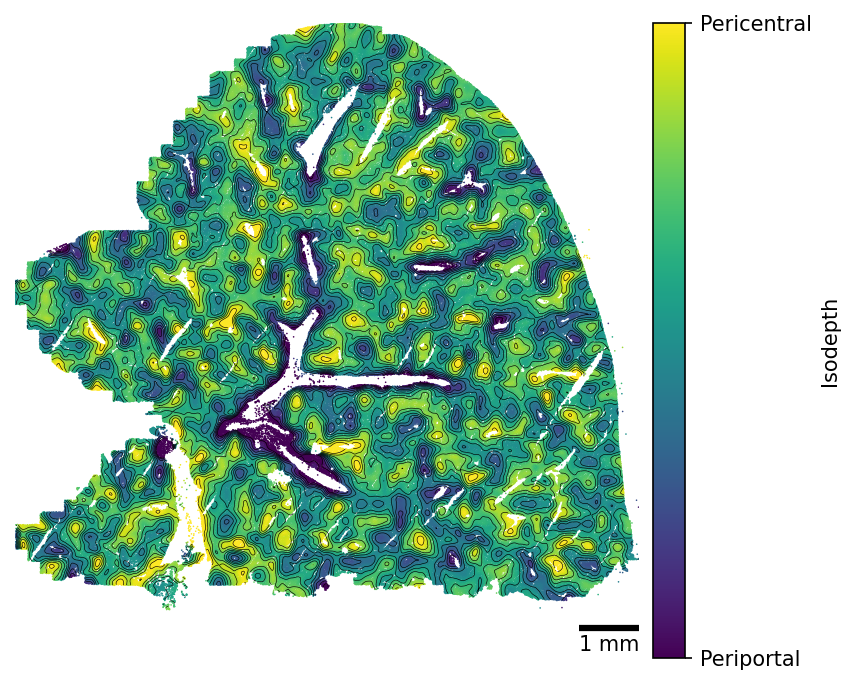

In [6]:
lo, hi = np.percentile(isodepth, [1, 99])

# drop triangles that span gaps in the tissue, so contours do not cross them
triangulation = mtri.Triangulation(coords[:, 0], coords[:, 1])
corners = coords[triangulation.triangles]
edges = np.stack([corners[:, 1] - corners[:, 0], corners[:, 2] - corners[:, 1],
                  corners[:, 0] - corners[:, 2]], axis=1)
longest = np.linalg.norm(edges, axis=2).max(axis=1)
triangulation.set_mask(longest > 3 * np.median(longest))

fig, ax = plt.subplots(figsize=(6, 5.5))
points = ax.scatter(*coords.T, c=isodepth, vmin=lo, vmax=hi, cmap="viridis",
                    s=0.6, linewidths=0, rasterized=True)
ax.tricontour(triangulation, isodepth, levels=np.linspace(lo, hi, 10),
              colors="black", linewidths=0.3)
ax.set_aspect("equal")
ax.axis("off")

x_end = coords[:, 0].max()
y_bar = coords[:, 1].min() - 300
ax.plot([x_end - 1000, x_end], [y_bar, y_bar], color="black", lw=3, solid_capstyle="butt")
ax.text(x_end - 500, y_bar - 120, "1 mm", ha="center", va="top")

colorbar = fig.colorbar(points, ax=ax, fraction=0.046, pad=0.02, ticks=[lo, hi])
colorbar.ax.set_yticklabels(["Periportal", "Pericentral"])
colorbar.set_label("Isodepth")
plt.show()

## 5. Example genes

We use two pericentral genes (Kit, Csnk1a1) and two periportal genes (Efnb2, Cxadr).

### f(d) curves and binned data

To compare `f(d)` with the data, we sort the cells between the 1st and 99th percentile of
the isodepth into bins of 2,000 cells. In each bin, we remove each cell's library size and
cell state term, then compare what is left with `f(d)` at the center of the bin:

`log( mean( (counts / library) / exp(h(z)) ) ) + mean(log Z)`

Here `Z` is the softmax normalizer of each cell.

179 bins


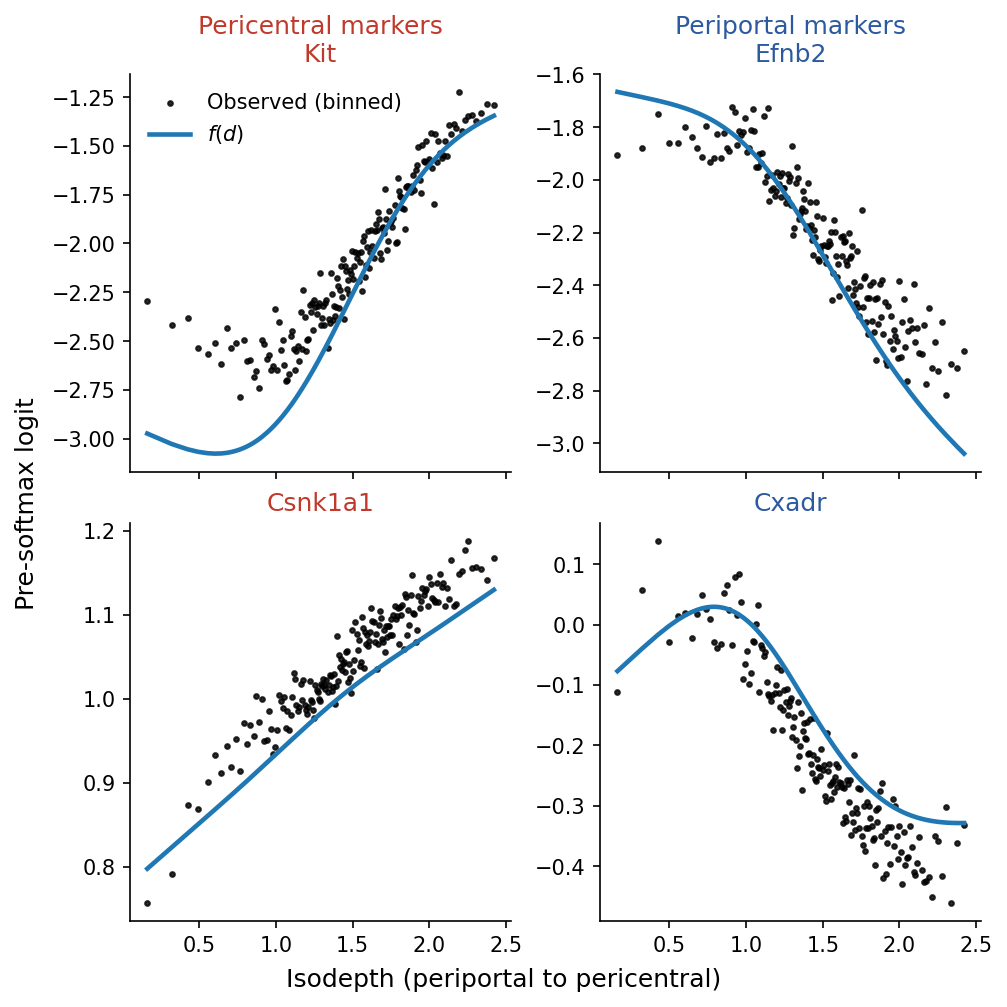

In [7]:
in_range = np.flatnonzero((d >= np.percentile(d, 1)) & (d <= np.percentile(d, 99)))
sorted_cells = in_range[np.argsort(d[in_range])]
bins = np.array_split(sorted_cells, len(sorted_cells) // 2000)
centers = np.array([d[cells].mean() for cells in bins])
curves = f_of_d(centers)  # (bins, genes)
log_Z = logsumexp(f_of_d(d) + h_of_z, axis=1)
print(f"{len(bins)} bins")

gene_grid = [["Kit", "Efnb2"], ["Csnk1a1", "Cxadr"]]
column_titles = ["Pericentral markers", "Periportal markers"]
column_colors = ["#C0392B", "#2C5AA0"]

fig, axes = plt.subplots(2, 2, figsize=(6.6, 6.6), sharex=True, constrained_layout=True)
for row in range(2):
    for col in range(2):
        gene, ax = gene_grid[row][col], axes[row, col]
        g = list(gene_names).index(gene)
        observed = [np.log(((counts[cells, g] / library[cells])
                            / np.exp(h_of_z[cells, g])).mean()) + log_Z[cells].mean()
                    for cells in bins]
        ax.scatter(direction * centers, observed, s=5, color="black", alpha=0.8,
                   label="Observed (binned)")
        ax.plot(direction * centers, curves[:, g], color="#1f77b4", lw=2.2, label="$f(d)$")
        ax.set_title(gene, color=column_colors[col])
        ax.spines[["top", "right"]].set_visible(False)
axes[0, 0].legend(frameon=False)
for col in range(2):
    axes[0, col].set_title(f"{column_titles[col]}\n{gene_grid[0][col]}", color=column_colors[col])
fig.supxlabel("Isodepth (periportal to pericentral)")
fig.supylabel("Pre-softmax logit")
plt.show()

### Raw expression maps

These maps show the raw `log1p` counts of the same genes on the tissue.

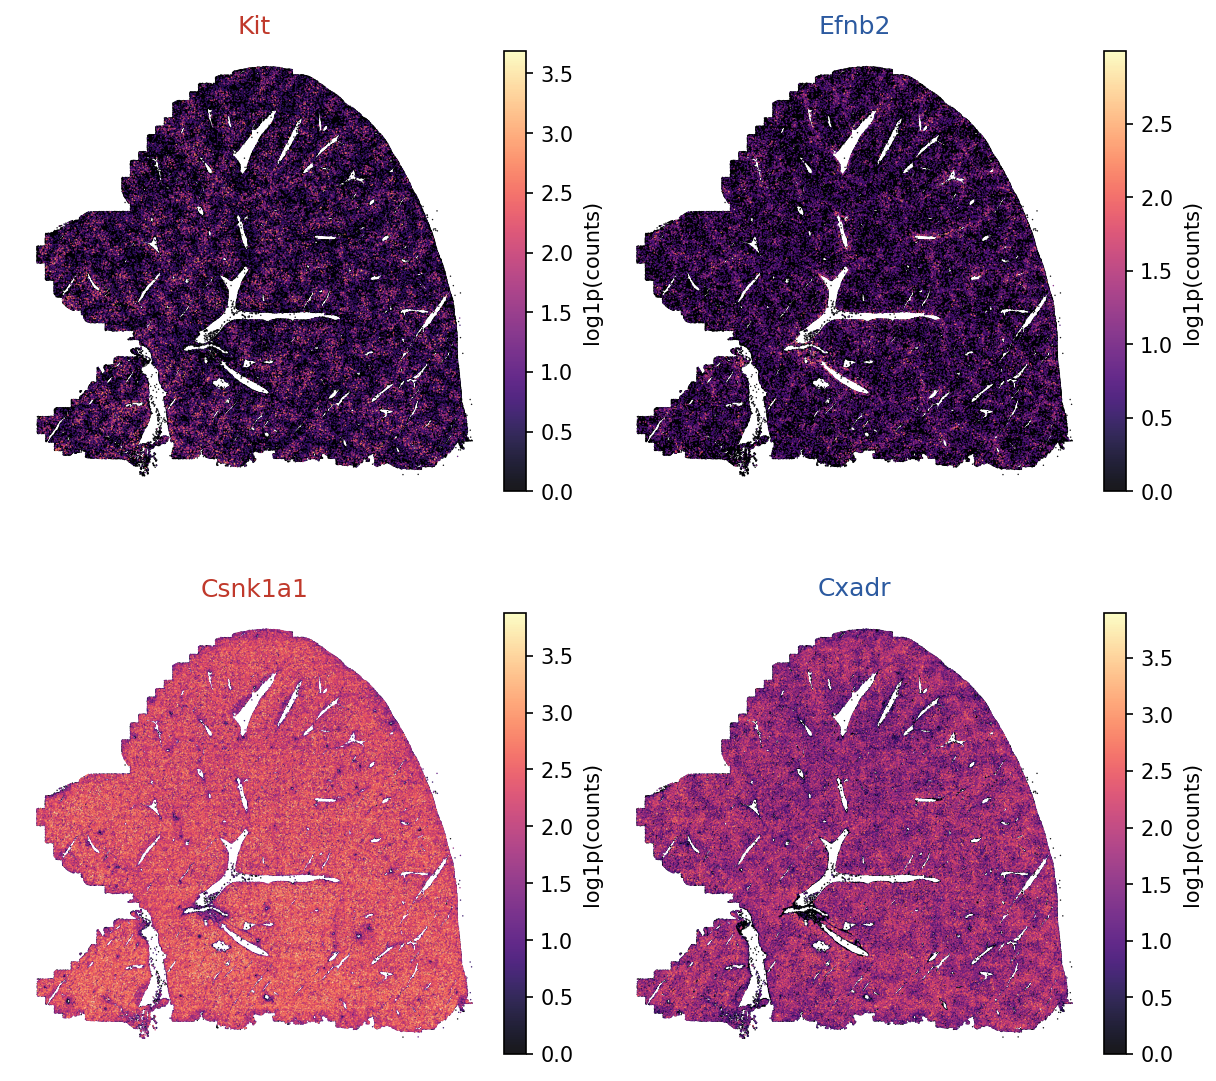

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(8, 7.5), constrained_layout=True)
for row in range(2):
    for col in range(2):
        gene, ax = gene_grid[row][col], axes[row, col]
        expression = np.log1p(counts[:, list(gene_names).index(gene)])
        order = np.argsort(expression)  # brightest cells on top
        points = ax.scatter(*coords[order].T, c=expression[order], cmap="magma",
                            vmin=0, s=0.5, alpha=0.9, linewidths=0, rasterized=True)
        ax.set_title(gene, color=column_colors[col])
        ax.set_aspect("equal")
        ax.axis("off")
        fig.colorbar(points, ax=ax, fraction=0.046, pad=0.02, label="log1p(counts)")
plt.show()